<a href="https://www.kaggle.com/code/manahil12/shoe-size-prediction-model-by-manahil-tahir?scriptVersionId=367053390" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/engraamirjamil/shoe-size-dataset/shoe_size_dataset.csv


<div style="background-color: #000080; color: white; padding: 25px; text-align: center; border-radius: 10px; font-size: 25px;">
    <h1 style="color: white; margin: 0; padding-bottom: 8px;">Shoe Size Prediction Model</h1>
    <p style="margin: 0; font-size: 16px; font-weight: bold; text-align:right;">By: Manahil Tahir</p>
</div>

## 1. Import and Setup

In [2]:
!pip install numpy pandas matplotlib seaborn scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, confusion_matrix


import warnings as w
w.filterwarnings('ignore')

import time as t
print(f"Last Update :  {t.asctime()}")

Last Update :  Sun Nov  8 19:44:19 2026


## 2. Load DataSet

In [3]:
df = pd.read_csv("/kaggle/input/datasets/engraamirjamil/shoe-size-dataset/shoe_size_dataset.csv")

In [4]:
df.head()

,height_cm,weight_kg,gender,shoe_size_us
0,177.4,96.8,Male,10.0
1,167.7,56.8,Female,6.0
2,156.6,66.4,Female,4.0
3,154.1,78.5,Female,4.0
4,183.3,73.3,Male,9.5


In [5]:
df.shape

(500, 4)

In [6]:
df.dtypes

height_cm       float64
weight_kg       float64
gender           object
shoe_size_us    float64
dtype: object

In [7]:
df.columns

Index(['height_cm', 'weight_kg', 'gender', 'shoe_size_us'], dtype='object')

In [8]:
df.isnull().sum()

height_cm       0
weight_kg       0
gender          0
shoe_size_us    0
dtype: int64

In [9]:
df.isnull().sum()

height_cm       0
weight_kg       0
gender          0
shoe_size_us    0
dtype: int64

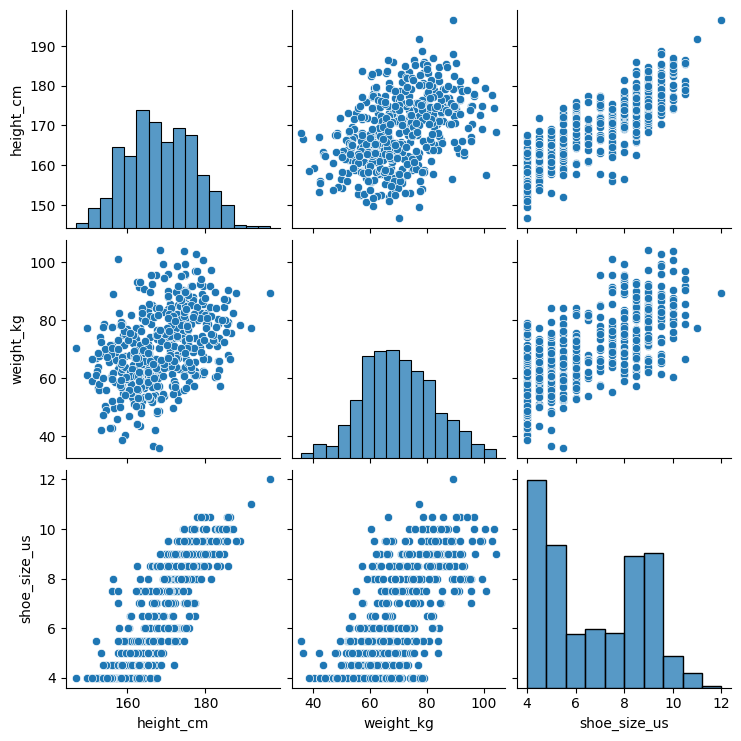

In [10]:
sns.pairplot(df)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   height_cm     500 non-null    float64
 1   weight_kg     500 non-null    float64
 2   gender        500 non-null    object 
 3   shoe_size_us  500 non-null    float64
dtypes: float64(3), object(1)
memory usage: 15.8+ KB


In [12]:
df['gender'] = df['gender'].map({
    'Male': 0,
    'Female': 1
})

In [13]:
df['gender'].value_counts()

gender
1    259
0    241
Name: count, dtype: int64

In [14]:
print(df['gender'].dtype)

int64


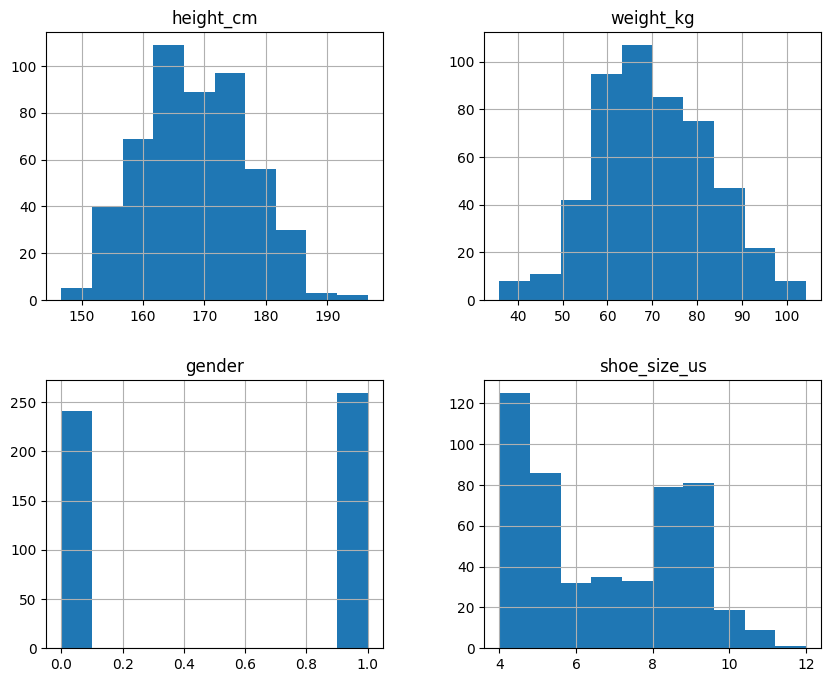

In [15]:
df.hist(figsize=(10, 8))
plt.show()

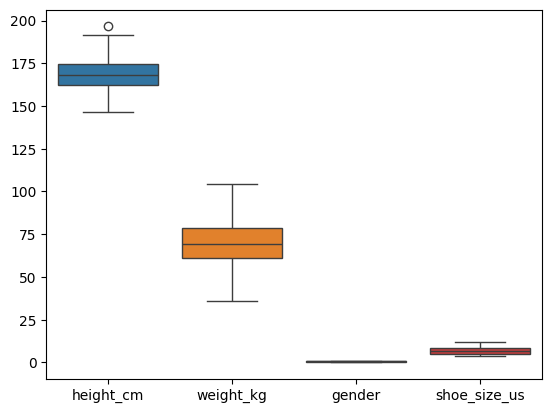

In [16]:
sns.boxplot(data=df.select_dtypes(include='number'))
plt.show()

In [17]:
q1 = df['height_cm'].quantile(0.25)
q3 = df['height_cm'].quantile(0.75)
iqr = q3 - q1

low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr

In [18]:
df = df[(df['height_cm'] >= low) & (df['height_cm'] <= high)]

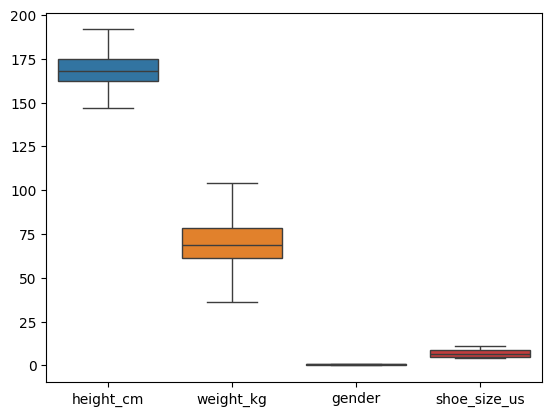

In [19]:
sns.boxplot(data=df.select_dtypes(include='number'))
plt.show()

## 3. Target and Split

In [20]:
X = df.drop('shoe_size_us', axis=1)
y = df['shoe_size_us']
X.shape, y.shape

((499, 3), (499,))

## 4. Encoding  the Target Feature 

In [21]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)

In [22]:
le.classes_

array([ 4. ,  4.5,  5. ,  5.5,  6. ,  6.5,  7. ,  7.5,  8. ,  8.5,  9. ,
        9.5, 10. , 10.5, 11. ])

In [23]:
y_encoded[:10]

array([12,  4,  0,  0, 11,  7, 12,  0,  1,  1])

## 5. Scalling the input Features

In [24]:
sc = StandardScaler()

In [25]:
x_scaled = sc.fit_transform(X)

## 6.Train, Test and Split

In [26]:
X = df[['height_cm', 'weight_kg', 'gender']]
y = df['shoe_size_us']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## 7. Model Training

In [27]:
model1 = LinearRegression()
model2 = DecisionTreeRegressor(random_state=42)
model3 = RandomForestRegressor(random_state=42)

In [28]:
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [29]:
y_pred1 = model1.predict(X_test)
y_pred2 = model2.predict(X_test)
y_pred3 = model3.predict(X_test)

In [30]:
print(y_pred1[:10])
print(y_pred2[:10])
print(y_pred3[:10])

[5.691904   4.47944958 4.35674157 6.19295712 6.30771581 9.44943466
 5.42529673 7.57017075 9.06016099 4.74603604]
[4.5 4.5 4.  6.  7.  8.  6.  8.  8.5 6. ]
[5.355 4.435 4.17  6.19  6.37  9.665 5.68  8.04  9.05  5.14 ]


## 8. Model Evaluation

In [31]:
print("Linear Regression:", round(model1.score(X_test, y_test) * 100), "%")
print("Decision Tree:", round(model2.score(X_test, y_test) * 100), "%")
print("Random Forest:", round(model3.score(X_test, y_test) * 100), "%")

Linear Regression: 92 %
Decision Tree: 85 %
Random Forest: 91 %


## 9. Regression report

In [32]:
def Regression_report(y_test, y_pred):
    print("MAE:", mean_absolute_error(y_test, y_pred))
    print("MSE:", mean_squared_error(y_test, y_pred))
    print("R2 Score:", r2_score(y_test, y_pred))

print("Linear Regression Report")
Regression_report(y_test, y_pred1)

print("\nDecision Tree Report")
Regression_report(y_test, y_pred2)

print("\nRandom Forest Report")
Regression_report(y_test, y_pred3)

Linear Regression Report
MAE: 0.5022053995923933
MSE: 0.38138009027163877
R2 Score: 0.9176089156664351

Decision Tree Report
MAE: 0.61
MSE: 0.7
R2 Score: 0.8487761671239387

Random Forest Report
MAE: 0.5102499999999999
MSE: 0.41861174999999995
R2 Score: 0.9095656095400635


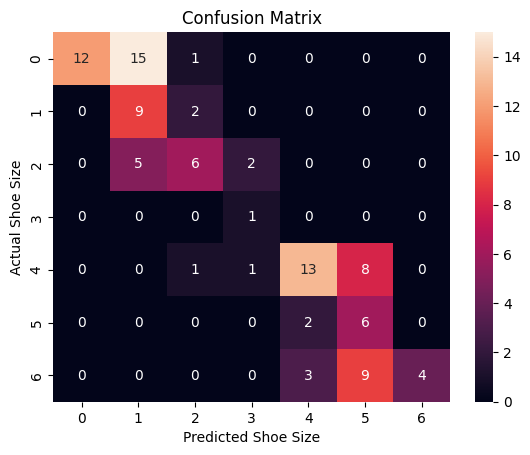

In [33]:
y_pred_class = np.round(y_pred1)
y_test_class = np.round(y_test)

cm = confusion_matrix(y_test_class, y_pred_class)

sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted Shoe Size')
plt.ylabel('Actual Shoe Size')
plt.title('Confusion Matrix')
plt.show()